# Projet final : les récoltes agricoles

**Équipe :** (nom de l'équipe et des 5 membres)

Une direction départementale de l'agriculture (fictive) vous confie trois ans de récoltes, de 2023 à 2025, par saison (printemps, automne), département et culture, avec la pluie tombée pendant chaque saison. Le ministère veut savoir quelles cultures pèsent le plus, où les rendements sont les meilleurs, et si la pluie explique les mauvaises années.

Ce notebook montre **votre démarche** : chaque étape dit ce que vous cherchez, le code, le résultat et ce que vous en concluez. Les graphiques doivent être visibles : avant de pousser, **Restart**, puis **Run All**.

Le tableau de bord (`app.py`) reprend ensuite vos résultats pour le décideur.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

brut = pd.read_csv("donnees/recoltes_brut.csv")

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, et toutes les écritures d'une même valeur dans les colonnes de texte. Notez chaque problème trouvé : vous le corrigerez à l'étape 2.

In [2]:
print("Forme :", brut.shape)
print()
print(brut.dtypes)
print()
print("Valeurs manquantes :")
print(brut.isna().sum())
print()
print("Lignes en double :", brut.duplicated().sum())

Forme : (408, 6)

annee           int64
saison            str
departement       str
culture           str
surface_ha        str
production_t      str
dtype: object

Valeurs manquantes :
annee            0
saison           0
departement      0
culture          0
surface_ha       0
production_t    15
dtype: int64

Lignes en double : 18


In [3]:
for colonne in ["saison", "departement", "culture"]:
    print(colonne, ":", brut[colonne].nunique(), "écritures différentes")
    print(brut[colonne].unique())
    print()

saison : 2 écritures différentes
<ArrowStringArray>
['Printemps', 'Automne']
Length: 2, dtype: str

departement : 44 écritures différentes
<ArrowStringArray>
[      'Ouest',      'Ouest ',       'ouest',  'Artibonite',        'Nord',
         'Sud',      'Centre',     ' Centre',  'NORD-OUEST',  'Nord-Ouest',
     'Sud-Est',    'Sud-Est ',  'Grand'Anse',  'grand'anse',  'GRAND'ANSE',
    'Nord-Est',      'Nippes',      'NIPPES',  'ARTIBONITE',        'NORD',
        'nord', 'Nord-Ouest ',  'nord-ouest', ' Nord-Ouest',    ' Sud-Est',
 ' Grand'Anse', 'Grand'Anse ',   'Nord-Est ',     'Nippes ',       'OUEST',
 ' Artibonite',       'Nord ',        ' Sud',     'sud-est',    'nord-est',
    'NORD-EST',      ' Ouest',         'SUD',  'artibonite',       ' Nord',
        'Sud ',         'sud',      'centre',   ' Nord-Est']
Length: 44, dtype: str

culture : 33 écritures différentes
<ArrowStringArray>
[      ' Maïs',      'Sorgho',         'Riz',     'Haricot',  'Pois congo',
      'banane',    

In [4]:
for colonne in ["surface_ha", "production_t"]:
    converti = pd.to_numeric(brut[colonne], errors="coerce")
    pas_nombre = converti.isna() & brut[colonne].notna()
    print(colonne, ":", pas_nombre.sum(), "valeurs non convertibles, par exemple :")
    print(brut.loc[pas_nombre, colonne].unique()[:8])
    print()

surface_ha : 22 valeurs non convertibles, par exemple :
<ArrowStringArray>
['2 517', '541 ha', '1 127', '1 185', '1 748', '492 ha', '997 ha', '1 050']
Length: 8, dtype: str

production_t : 50 valeurs non convertibles, par exemple :
<ArrowStringArray>
['3753 t', '2299 t', '1306 t', '2394 t', '599 t', '767 t', '8147 t', '2089 t']
Length: 8, dtype: str



**Problèmes trouvés :**
1. `surface_ha` et `production_t` sont du texte : des unités (« ha », « t ») et des espaces dans les nombres.
2. Les départements (44 écritures pour 10) et les cultures (33 pour 7) sont écrits de plusieurs façons : espaces et majuscules.
3. 15 productions manquantes.
4. 18 lignes en double.

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème, en comptant les lignes avant et après chaque suppression. Dites ce que vous supprimez et pourquoi.

**Contrôle :** à la fin, `propre.shape` vaut `(376, 6)`, sans valeur manquante ni doublon, avec 2 valeurs dans `saison`, 10 valeurs dans `departement`, 7 valeurs dans `culture`.

In [5]:
propre = brut.copy()
print("Lignes au départ :", len(propre))

Lignes au départ : 408


In [6]:
departements = pd.read_csv("donnees/departements.csv")
cultures = pd.read_csv("donnees/cultures.csv")

noms_dep = dict(zip(departements["departement"].str.lower(), departements["departement"]))
noms_cult = dict(zip(cultures["culture"].str.lower(), cultures["culture"]))

propre["departement"] = propre["departement"].str.strip().str.lower().map(noms_dep)
propre["culture"] = propre["culture"].str.strip().str.lower().map(noms_cult)

print("Départements :", propre["departement"].nunique(), "| perdus :", propre["departement"].isna().sum())
print("Cultures :", propre["culture"].nunique(), "| perdues :", propre["culture"].isna().sum())

Départements : 10 | perdus : 0
Cultures : 7 | perdues : 0


In [7]:
propre["surface_ha"] = pd.to_numeric(propre["surface_ha"].str.replace("ha", "").str.replace(" ", ""))
propre["production_t"] = pd.to_numeric(propre["production_t"].str.replace("t", "").str.replace(" ", ""))

print(propre.dtypes)
print("Manquants :")
print(propre.isna().sum())

annee             int64
saison              str
departement         str
culture             str
surface_ha        int64
production_t    float64
dtype: object
Manquants :
annee            0
saison           0
departement      0
culture          0
surface_ha       0
production_t    15
dtype: int64


In [8]:
avant = len(propre)
propre = propre.drop_duplicates()
print("Avant :", avant, "| après :", len(propre), "| doublons supprimés :", avant - len(propre))

Avant : 408 | après : 390 | doublons supprimés : 18


In [9]:
avant = len(propre)
propre = propre.dropna(subset=["production_t"])
print("Avant :", avant, "| après :", len(propre), "| lignes supprimées :", avant - len(propre))

Avant : 390 | après : 376 | lignes supprimées : 14


In [10]:
print("Forme :", propre.shape)
print("Manquants :", propre.isna().sum().sum())
print("Doublons :", propre.duplicated().sum())
print("Saisons :", propre["saison"].nunique())
print("Départements :", propre["departement"].nunique())
print("Cultures :", propre["culture"].nunique())

Forme : (376, 6)
Manquants : 0
Doublons : 0
Saisons : 2
Départements : 10
Cultures : 7


**Ce que nous avons supprimé :**
- 18 doublons : la même récolte saisie deux fois, qui aurait compté double dans les totaux.
- 14 lignes sans production : sans tonnage, on ne peut calculer ni le rendement ni la valeur. On ne les remplace pas, pour ne pas inventer de chiffres.

Il reste 376 lignes, propres, sur les 408 du départ.

## 3. Jointures

Joignez `propre` avec `cultures.csv`, `pluies.csv`, et ajoutez les colonnes calculées dont vous aurez besoin. Comptez les lignes avant et après chaque `merge`.

**Contrôle :** 376 lignes après les jointures, autant qu'avant.

In [11]:
pluies = pd.read_csv("donnees/pluies.csv")

print("Avant :", len(propre))

complet = propre.merge(cultures, on="culture", how="left")
print("Après cultures :", len(complet))

complet = complet.merge(pluies, on=["annee", "saison", "departement"], how="left")
print("Après pluies :", len(complet))

complet = complet.merge(departements, on="departement", how="left")
print("Après départements :", len(complet))

print()
print("Manquants après jointures :")
print(complet.isna().sum())

Avant : 376
Après cultures : 376
Après pluies : 376
Après départements : 376

Manquants après jointures :
annee                   0
saison                  0
departement             0
culture                 0
surface_ha              0
production_t            0
famille                 0
rendement_moyen_t_ha    0
prix_htg_kg             0
pluie_mm                0
chef_lieu               0
population              0
superficie_km2          0
dtype: int64


Enregistrez le tableau complet : c'est le fichier que lit le tableau de bord.

```python
complet.to_csv("donnees/recoltes_propre.csv", index=False)
```

In [12]:
complet["rendement_t_ha"] = complet["production_t"] / complet["surface_ha"]
complet["valeur_htg"] = complet["production_t"] * 1000 * complet["prix_htg_kg"]
complet["production_kg_hab"] = complet["production_t"] * 1000 / complet["population"]

print(complet.shape)
complet.head()

(376, 16)


,annee,saison,departement,culture,surface_ha,production_t,famille,rendement_moyen_t_ha,prix_htg_kg,pluie_mm,chef_lieu,population,superficie_km2,rendement_t_ha,valeur_htg,production_kg_hab
0,2023,Printemps,Ouest,Maïs,1488,1327.0,céréale,1.1,22.0,369,Port-au-Prince,4029705,4983,0.891801,29194000.0,0.329305
1,2023,Printemps,Ouest,Sorgho,3577,2629.0,céréale,0.9,20.0,369,Port-au-Prince,4029705,4983,0.734973,52580000.0,0.652405
2,2023,Printemps,Ouest,Riz,2453,6122.0,céréale,2.6,38.0,369,Port-au-Prince,4029705,4983,2.495720,232636000.0,1.519218
3,2023,Printemps,Ouest,Haricot,814,464.0,légumineuse,0.7,65.0,369,Port-au-Prince,4029705,4983,0.570025,30160000.0,0.115145
4,2023,Printemps,Ouest,Pois congo,2436,1710.0,légumineuse,0.8,55.0,369,Port-au-Prince,4029705,4983,0.701970,94050000.0,0.424349


In [13]:
complet.to_csv("donnees/recoltes_propre.csv", index=False)

relu = pd.read_csv("donnees/recoltes_propre.csv")
print(relu.shape)

(376, 16)


## 4. Quelles cultures pèsent le plus, en tonnes puis en valeur (gourdes) ? Le classement change-t-il ?

In [14]:
par_culture = complet.groupby("culture").agg(
    tonnes=("production_t", "sum"),
    valeur_htg=("valeur_htg", "sum"),
)
par_culture["valeur_millions_htg"] = (par_culture["valeur_htg"] / 1_000_000).round(1)
par_culture["rang_tonnes"] = par_culture["tonnes"].rank(ascending=False).astype(int)
par_culture["rang_valeur"] = par_culture["valeur_htg"].rank(ascending=False).astype(int)

par_culture.sort_values("tonnes", ascending=False)[
    ["tonnes", "rang_tonnes", "valeur_millions_htg", "rang_valeur"]
]

,tonnes,rang_tonnes,valeur_millions_htg,rang_valeur
culture,,,,
Banane,547615.0,1,6571.4,2
Igname,402302.0,2,12069.1,1
Riz,136225.0,3,5176.6,3
Maïs,75311.0,4,1656.8,6
Sorgho,61354.0,5,1227.1,7
Pois congo,56626.0,6,3114.4,4
Haricot,42323.0,7,2751.0,5


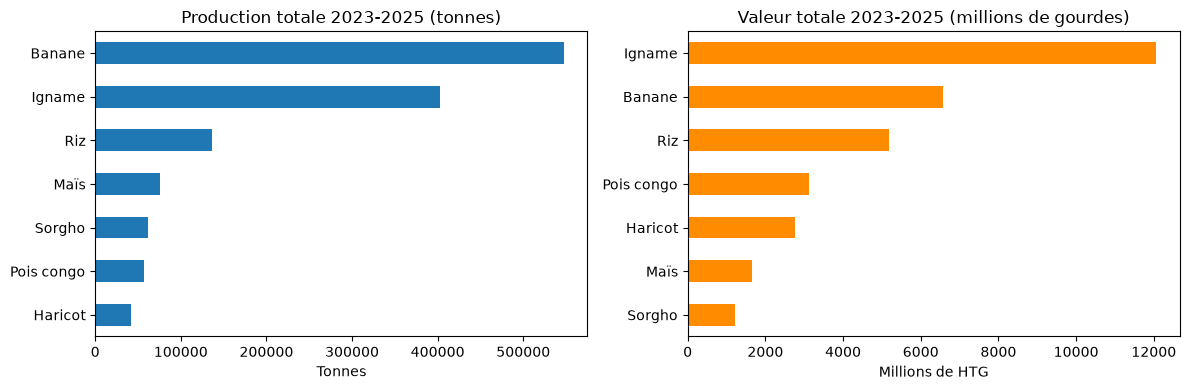

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

par_culture["tonnes"].sort_values().plot.barh(ax=ax1)
ax1.set_title("Production totale 2023-2025 (tonnes)")
ax1.set_xlabel("Tonnes")
ax1.set_ylabel("")

par_culture["valeur_millions_htg"].sort_values().plot.barh(ax=ax2, color="darkorange")
ax2.set_title("Valeur totale 2023-2025 (millions de gourdes)")
ax2.set_xlabel("Millions de HTG")
ax2.set_ylabel("")

plt.tight_layout()
plt.show()

**Ce qu'on en conclut :**

Le classement change. La banane est la première culture en tonnes (547 615 t sur 2023-2025), mais l’igname est la première en valeur (12 069 millions de gourdes, presque le double de la banane), car elle se vend plus cher au kilo. 

## 5. Où les rendements (tonnes par hectare) sont-ils les meilleurs, culture par culture ?

In [16]:
sommes = complet.groupby(["culture", "departement"])[["production_t", "surface_ha"]].sum()
sommes["rendement"] = sommes["production_t"] / sommes["surface_ha"]
rendements = sommes["rendement"].unstack().round(2)
rendements

departement,Artibonite,Centre,Grand'Anse,Nippes,Nord,Nord-Est,Nord-Ouest,Ouest,Sud,Sud-Est
culture,,,,,,,,,,
Banane,7.10,6.64,8.66,7.21,9.05,6.23,6.55,6.89,8.01,7.04
Haricot,0.64,0.78,0.69,0.71,0.70,0.61,0.60,0.63,0.88,0.66
Igname,5.79,5.53,8.24,5.30,5.74,5.32,5.44,5.74,6.56,5.76
Maïs,0.96,1.20,1.11,1.05,1.08,0.91,0.99,1.06,1.15,0.92
Pois congo,0.77,0.82,0.73,0.76,0.74,0.63,1.01,0.80,0.80,0.76
Riz,3.80,NaN,NaN,NaN,2.43,2.12,NaN,2.38,2.68,NaN
Sorgho,0.79,1.08,0.91,0.85,0.90,0.77,0.82,0.83,0.80,0.88


In [17]:
meilleurs = pd.DataFrame({
    "meilleur_departement": rendements.idxmax(axis=1),
    "rendement_t_ha": rendements.max(axis=1),
    "rendement_moyen_t_ha": cultures.set_index("culture")["rendement_moyen_t_ha"],
})
meilleurs["ecart_%"] = ((meilleurs["rendement_t_ha"] / meilleurs["rendement_moyen_t_ha"] - 1) * 100).round(1)
meilleurs

,meilleur_departement,rendement_t_ha,rendement_moyen_t_ha,ecart_%
culture,,,,
Banane,Nord,9.05,7.5,20.7
Haricot,Sud,0.88,0.7,25.7
Igname,Grand'Anse,8.24,6.0,37.3
Maïs,Centre,1.20,1.1,9.1
Pois congo,Nord-Ouest,1.01,0.8,26.2
Riz,Artibonite,3.80,2.6,46.2
Sorgho,Centre,1.08,0.9,20.0


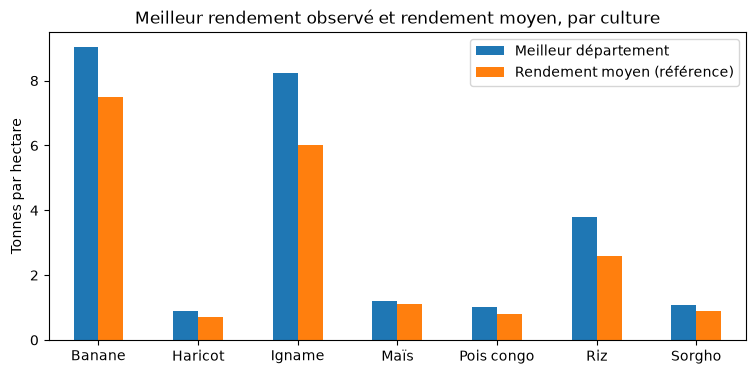

In [18]:
ax = meilleurs[["rendement_t_ha", "rendement_moyen_t_ha"]].plot.bar(figsize=(9, 4), rot=0)
ax.set_title("Meilleur rendement observé et rendement moyen, par culture")
ax.set_xlabel("")
ax.set_ylabel("Tonnes par hectare")
ax.legend(["Meilleur département", "Rendement moyen (référence)"])
plt.show()

**Ce qu'on en conclut :**

Il n’y a pas un seul département qui a les meilleurs rendements pour tout : chaque culture a son département, seul le Centre est en tête deux fois (maïs et sorgho).

## 6. La pluie explique-t-elle les rendements ? Pour quelles cultures ? Montrez-le avec des nuages de points.

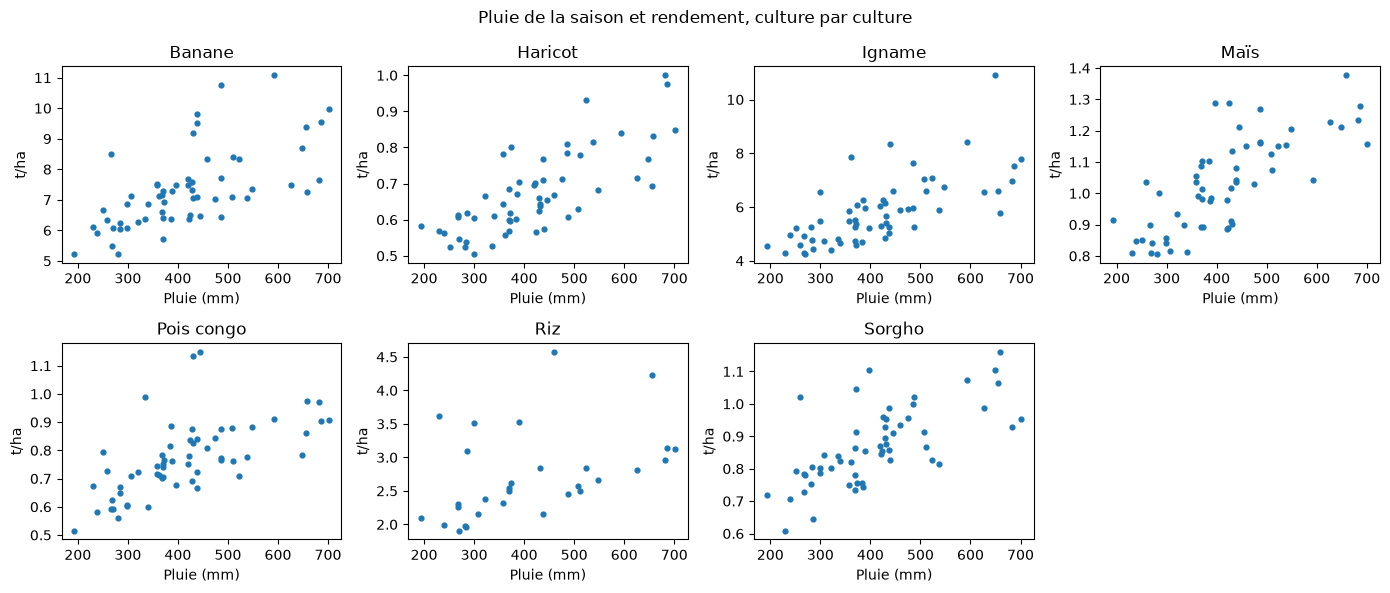

In [19]:
liste_cultures = sorted(complet["culture"].unique())
fig, axes = plt.subplots(2, 4, figsize=(14, 6))

for ax, nom in zip(axes.flat, liste_cultures):
    une = complet[complet["culture"] == nom]
    ax.scatter(une["pluie_mm"], une["rendement_t_ha"], s=12)
    ax.set_title(nom)
    ax.set_xlabel("Pluie (mm)")
    ax.set_ylabel("t/ha")

axes.flat[-1].set_visible(False)
fig.suptitle("Pluie de la saison et rendement, culture par culture")
plt.tight_layout()
plt.show()

In [20]:
correlations = pd.Series({
    nom: une["pluie_mm"].corr(une["rendement_t_ha"])
    for nom, une in complet.groupby("culture")
}).round(2).sort_values(ascending=False)
correlations

Haricot       0.76
Maïs          0.76
Igname        0.69
Sorgho        0.68
Banane        0.65
Pois congo    0.63
Riz           0.42
dtype: float64

**Ce qu'on en conclut :**

Oui, la pluie va avec de meilleurs rendements, pour toutes les cultures : les corrélations sont toutes positives, de 0.76 pour le haricot et le maïs à 0.42 pour le riz

## 7. Quelles cultures progressent ou reculent entre 2023 et 2025 ?

In [21]:
par_annee = complet.pivot_table(index="culture", columns="annee", values="production_t", aggfunc="sum")
par_annee["evolution_%"] = ((par_annee[2025] / par_annee[2023] - 1) * 100).round(1)
par_annee.sort_values("evolution_%", ascending=False)

annee,2023,2024,2025,evolution_%
culture,,,,
Riz,44064.0,39660.0,52501.0,19.1
Sorgho,20478.0,16785.0,24091.0,17.6
Banane,182892.0,166401.0,198322.0,8.4
Pois congo,17484.0,22271.0,16871.0,-3.5
Maïs,27006.0,24333.0,23972.0,-11.2
Haricot,16081.0,12159.0,14083.0,-12.4
Igname,161924.0,130569.0,109809.0,-32.2


**Ce qu'on en conclut :**

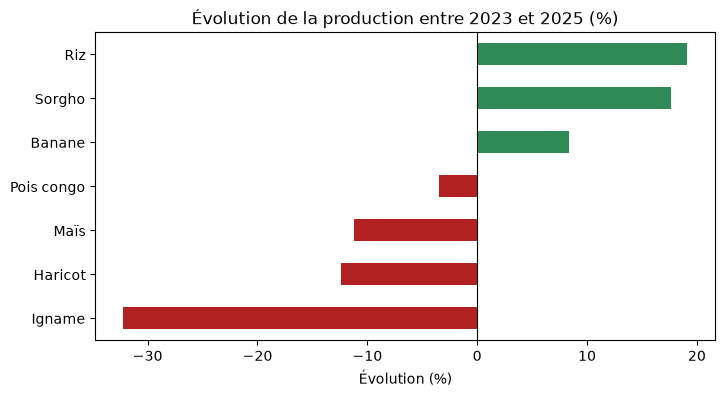

In [22]:
evolution = par_annee["evolution_%"].sort_values()
couleurs = ["firebrick" if valeur < 0 else "seagreen" for valeur in evolution]

ax = evolution.plot.barh(color=couleurs, figsize=(8, 4))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Évolution de la production entre 2023 et 2025 (%)")
ax.set_xlabel("Évolution (%)")
ax.set_ylabel("")
plt.show()

## 8. Rapportez la production à la population de chaque département : quels départements produisent le plus par habitant ?

In [23]:
nb_annees = complet["annee"].nunique()

par_dep = complet.groupby("departement")["production_t"].sum().to_frame("tonnes")
par_dep = par_dep.join(departements.set_index("departement")["population"])
par_dep["kg_par_hab_par_an"] = (par_dep["tonnes"] * 1000 / nb_annees / par_dep["population"]).round(1)
par_dep["rang_tonnes"] = par_dep["tonnes"].rank(ascending=False).astype(int)
par_dep["rang_kg_par_hab"] = par_dep["kg_par_hab_par_an"].rank(ascending=False).astype(int)
par_dep.sort_values("kg_par_hab_par_an", ascending=False)

,tonnes,population,kg_par_hab_par_an,rang_tonnes,rang_kg_par_hab
departement,,,,,
Grand'Anse,114384.0,468301,81.4,6,1
Centre,167080.0,746236,74.6,3,2
Sud,155168.0,774976,66.7,4,3
Nord-Est,75030.0,393967,63.5,9,4
Artibonite,269226.0,1727524,51.9,1,5
Nippes,49223.0,342525,47.9,10,6
Sud-Est,80796.0,632601,42.6,8,7
Nord-Ouest,87192.0,728807,39.9,7,8
Nord,118791.0,1067177,37.1,5,9


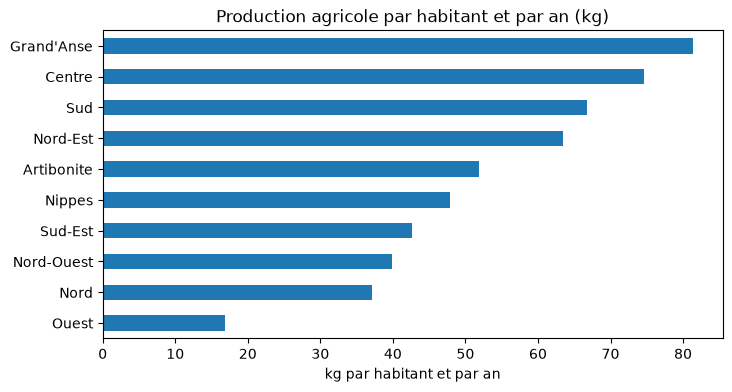

In [24]:
ax = par_dep["kg_par_hab_par_an"].sort_values().plot.barh(figsize=(8, 4))
ax.set_title("Production agricole par habitant et par an (kg)")
ax.set_xlabel("kg par habitant et par an")
ax.set_ylabel("")
plt.show()

**Ce qu'on en conclut :**

Grand’Anse est le département qui produit le plus par habitant (81.4 kg par an), devant le Centre (74.6) et le Sud (66.7). Le classement par habitant est très différent du classement en tonnes : l’Artibonite, premier en tonnes, n’est que 5ᵉ, et l’Ouest, 2ᵉ en tonnes, est dernier avec 16.9 kg par habitant, à cause de sa population de plus de 4 millions d’habitants

## 9. Conclusion

La banane pèse le plus en tonnes (547 615 t sur 2023-2025), mais l'igname passe en tête en valeur (12 069 millions de gourdes) parce qu'elle se vend plus cher au kilo, et elle recule de 32,2 % entre 2023 et 2025. Aucun département n'a les meilleurs rendements partout : chaque culture a le sien, et la pluie va avec de meilleurs rendements pour toutes les cultures (corrélations de 0,42 pour le riz à 0,76 pour le haricot et le maïs). Par habitant, Grand'Anse produit le plus (81,4 kg par an) et l'Ouest le moins (16,9 kg), alors qu'il est 2e en tonnes : le classement dépend de la population. Les données ne permettent pas de dire que la pluie *cause* les rendements (on mesure un lien, pas une cause), ni de prévoir l'avenir : il n'y a que trois ans, un seul prix par culture et une seule valeur de pluie par département et par saison. Il faudrait mesurer ensuite le sol, l'irrigation, les semences, les prix réels de chaque année, et ajouter plus d'années de récoltes.